In [43]:
import pandas as  pd 
import numpy as np 
import seaborn as sns  
import matplotlib.pyplot as plt 

import warnings 
warnings.filterwarnings("ignore")  

In [135]:
train=pd.read_csv('./dataset/train.csv')
sub=pd.read_csv('./dataset/sample_submission.csv')

In [45]:
train.head()

,ID_Date,StateCode,StationId,Date,PM2.5,PM10,O3,CO,SO2,AQI
0,AS_4_2021-08-17,AS,4,2021-08-17,51.8364,120.3702,18.0234,0.4896,14.3106,94.0
1,AS_4_2021-08-18,AS,4,2021-08-18,59.4762,87.0978,34.5270,0.4794,14.7594,124.0
2,AS_4_2021-08-19,AS,4,2021-08-19,61.0776,79.6008,42.0546,0.5202,16.7484,82.0
3,AS_4_2021-08-20,AS,4,2021-08-20,56.7222,94.2072,45.7878,0.4998,27.6114,107.0
4,AS_4_2021-08-21,AS,4,2021-08-21,85.3332,136.7820,44.5638,1.1118,26.4180,107.0


In [136]:
sub.head()

,ID_Date,AQI
0,AS_4_2022-12-04,10.0
1,AS_4_2022-12-05,10.0
2,AS_4_2022-12-06,10.0
3,AS_4_2022-12-07,10.0
4,AS_4_2022-12-08,10.0


In [46]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25340 entries, 0 to 25339
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID_Date    25340 non-null  object 
 1   StateCode  25340 non-null  object 
 2   StationId  25340 non-null  int64  
 3   Date       25340 non-null  object 
 4   PM2.5      25339 non-null  float64
 5   PM10       25338 non-null  float64
 6   O3         25324 non-null  float64
 7   CO         25339 non-null  float64
 8   SO2        25340 non-null  float64
 9   AQI        25340 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 1.9+ MB


Data Analysis-EDA

In [47]:
train.isnull().sum()

ID_Date       0
StateCode     0
StationId     0
Date          0
PM2.5         1
PM10          2
O3           16
CO            1
SO2           0
AQI           0
dtype: int64

In [87]:
train['PM2.5'] = train['PM2.5'].fillna(train['PM2.5'].mean())
train['PM10'] = train['PM10'].fillna(train['PM10'].mean())
train['O3'] = train['O3'].fillna(train['O3'].mean())
train['CO'] = train['CO'].fillna(train['CO'].mean())

In [48]:
train.describe()

,StationId,PM2.5,PM10,O3,CO,SO2,AQI
count,25340.000000,25339.000000,25338.000000,25324.000000,25339.000000,25340.000000,25340.000000
mean,19.700552,84.722233,176.876226,36.328698,1.135535,12.531818,190.841555
std,11.000809,80.605257,132.003679,23.356473,0.759970,8.917706,127.643584
min,4.000000,0.199500,0.220500,0.052500,0.000000,0.010500,14.000000
25%,11.000000,30.280000,73.751550,18.647400,0.612000,6.293400,91.000000
50%,16.000000,58.027800,142.509300,31.951500,0.969000,10.830000,152.000000
75%,29.000000,109.168500,247.224000,49.600500,1.459500,16.605600,276.000000
max,41.000000,935.003400,1020.000000,194.146800,8.863800,166.943400,975.000000


In [138]:
train['StateCode'].value_counts()

StateCode
DL    15862
KA     3445
MH     2819
WB     2056
TN      694
AS      464
Name: count, dtype: int64

In [142]:
train['StationId'].unique()

array([ 4,  6,  8, 12, 13, 18, 19, 21, 23, 25, 26, 27, 29, 30, 32, 35, 38,
       39, 40, 41,  7,  9, 10, 11, 14, 15, 16, 17,  5], dtype=int64)

In [143]:
train['StationId'].nunique()

29

In [144]:
train[train.isnull().any(axis=1)].sort_values(by=['StateCode', 'Date'])

,ID_Date,StateCode,StationId,Date,PM2.5,PM10,O3,CO,SO2,AQI
1024,DL_6_2020-08-02,DL,6,2020-08-02,187.25,359.17,NaN,0.97,11.00,376.0
2547,DL_12_2020-08-02,DL,12,2020-08-02,NaN,338.44,4.00,1.58,27.68,311.0
4221,DL_18_2020-08-02,DL,18,2020-08-02,200.96,393.25,NaN,1.53,12.11,427.0
5058,DL_19_2020-08-02,DL,19,2020-08-02,185.79,337.06,NaN,1.91,12.98,346.0
7419,DL_25_2020-08-02,DL,25,2020-08-02,126.30,209.51,NaN,0.59,4.24,312.0
8256,DL_26_2020-08-02,DL,26,2020-08-02,149.71,239.92,NaN,0.78,9.67,333.0
9093,DL_27_2020-08-02,DL,27,2020-08-02,160.07,273.29,NaN,0.87,3.40,338.0
10767,DL_30_2020-08-02,DL,30,2020-08-02,144.05,355.21,NaN,1.50,6.72,360.0
14652,DL_40_2020-08-02,DL,40,2020-08-02,140.67,283.33,NaN,0.74,12.49,330.0
1025,DL_6_2020-08-03,DL,6,2020-08-03,146.50,299.54,NaN,0.85,14.29,329.0


Most of the data is missed from delhi

In [145]:
# Check the statistics for releveant features
relevant_cols = ['PM2.5', 'PM10', 'O3', 'CO', 'SO2', 'AQI']

In [148]:
# Mean statewise 
grouped = train.groupby(by=["StateCode"])
grouped[relevant_cols].agg(['mean', 'median'])

PM2.5                 PM10                    O3            \
                 mean   median        mean     median       mean    median   
StateCode                                                                    
AS          68.673807  52.3209  125.605026  100.96470  25.686966  19.80300   
DL         109.444961  81.7632  226.827221  201.31890  37.457291  33.14425   
KA          32.610387  30.4500   75.320821   72.45000  40.486084  36.58740   
MH          39.869489  23.5824   96.970733   75.04350  26.632071  19.57200   
TN          28.636210  25.5780   60.779362   45.20775  48.380022  38.95935   
WB          65.368235  45.6330  121.889471   84.84000  32.293213  30.75300   

                 CO                SO2                   AQI         
               mean  median       mean    median        mean median  
StateCode                                                            
AS         0.774790  0.6300  15.032071  14.31570  150.309806  106.0  
DL         1.346106  1.1526  14.730964  13.19425  238.388854  213.0  
KA         0.907938  0.7956   6.210320   5.10000   91.252250   89.0  
MH         0.585328  0.4488  10.681013   7.70700  109.768269   91.0  
TN         0.799319  0.7140   9.277744   9.18000   90.245677   80.0  
WB         0.841527  0.6720   9.229447   7.37460  145.148833   98.0

In [157]:
# Let's explore year and month wise 
import datetime as dt

from matplotlib import dates as mdates
from collections import defaultdict


In [165]:
train.groupby(by=['year', 'month', 'StateCode', 'StationId'])[relevant_cols].agg(['mean', 'median'])

PM2.5                  PM10            \
                                      mean    median        mean    median   
year month StateCode StationId                                               
2020 8     DL        6          170.068519  172.4600  326.534444  332.7900   
                     12          54.233846   56.4850  269.302593  294.0400   
                     13         169.362593  167.5800  398.277037  389.1800   
                     18         214.854444  218.0400  391.083704  393.2500   
                     19         153.302963  159.4100  279.169259  284.3800   
...                                    ...       ...         ...       ...   
2022 12    TN        8           13.471500   13.2825   24.087000   24.9795   
           WB        12          16.023000   16.0335   43.816500   43.1970   
                     13          11.599000   12.1590   30.282000   29.2635   
                     14          16.334500   16.5795   34.345500   33.5895   
                     16          16.194500   16.6215   30.180500   30.5340   

                                       O3                 CO          \
                                     mean   median      mean  median   
year month StateCode StationId                                         
2020 8     DL        6          34.932400  37.7800  1.095556  0.9600   
                     12         49.191852  54.0800  1.575556  1.4300   
                     13         37.671111  41.6000  2.381481  2.2400   
                     18         13.683200  12.8100  1.734444  1.6100   
                     19         33.458400  37.0000  2.090370  1.6800   
...                                   ...      ...       ...     ...   
2022 12    TN        8          18.987500  18.4065  1.046500  1.0395   
           WB        12          7.416500   4.7250  0.329000  0.3360   
                     13         37.387000  38.0415  0.462000  0.4620   
                     14         72.971500  73.7835  0.273000  0.2625   
                     16         31.482500  30.0510  0.644000  0.6615   

                                      SO2                  AQI         
                                     mean   median        mean median  
year month StateCode StationId                                         
2020 8     DL        6          10.159259  10.4400  335.703704  344.0  
                     12         33.927037  34.3600  234.925926  252.0  
                     13          4.827037   4.8300  380.333333  391.0  
                     18         11.866296  11.6200  392.666667  378.0  
                     19         18.390370  18.2700  311.185185  330.0  
...                                   ...      ...         ...    ...  
2022 12    TN        8           5.796000   5.8170   55.000000   55.0  
           WB        12          3.328500   2.7405   43.666667   44.0  
                     13          7.661500   7.6335   50.333333   51.0  
                     14         12.138000  12.1590  115.666667  107.0  
                     16          8.057000   7.4235   43.000000   41.0  

[893 rows x 12 columns]

VISUALISATION

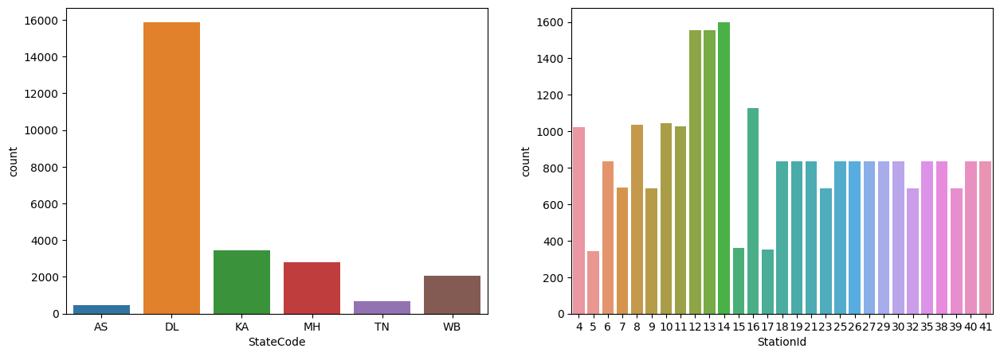

In [171]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
sns.countplot(x=train['StateCode'], ax=axes[0])
sns.countplot(x=train['StationId'], ax=axes[1])
plt.show()

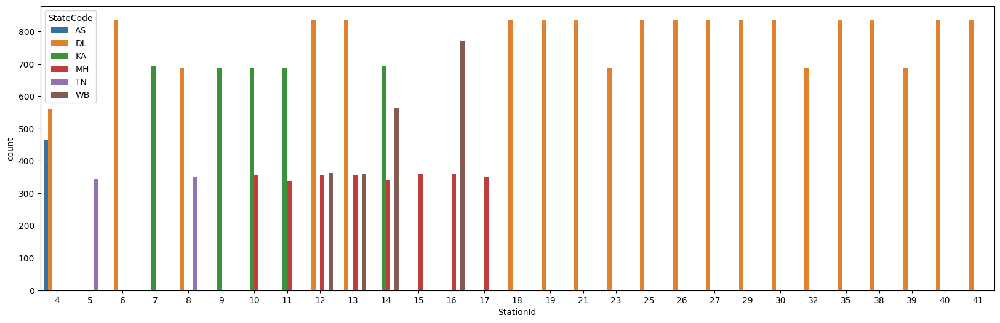

In [172]:
fig = plt.figure(figsize=(20,6))
sns.countplot(x=train.StationId, hue=train.StateCode)
plt.show()

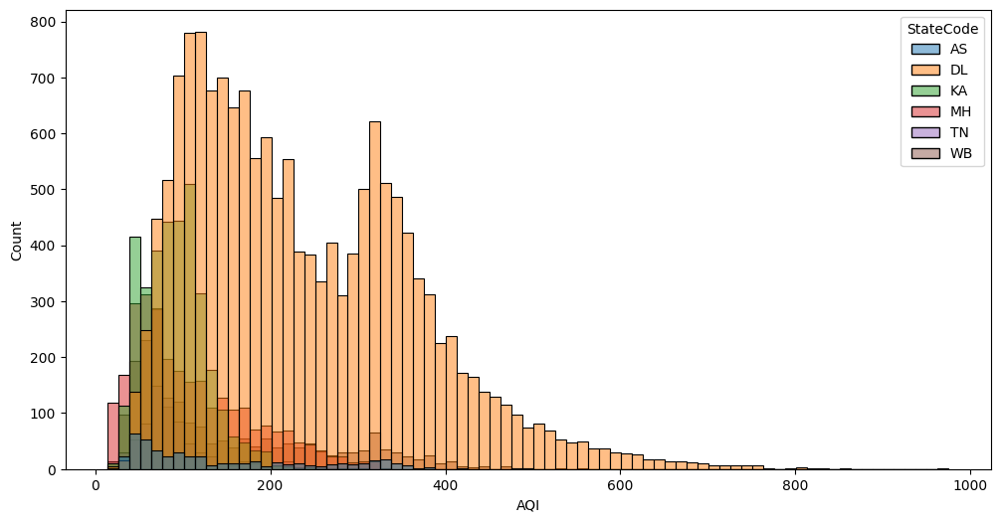

In [174]:
fig = plt.figure(figsize=(12,6))
sns.histplot(x=train.AQI, hue=train.StateCode)
plt.show()

In [175]:
# Combine statecode and stationid
train['StateStation'] = train.apply(lambda x: x['StateCode'] + "-" + str(x['StationId']), axis=1)

In [178]:
df = train.copy(deep=True)
df.set_index("Date", inplace=True)

In [179]:
# Set formaters for date type in plots
years = mdates.YearLocator()
months = mdates.MonthLocator()
monthsFmt = mdates.DateFormatter('%B')
yearsFmt = mdates.DateFormatter('\n%Y')

In [180]:
mapping = defaultdict(list)
for idx, code in enumerate(df.StateCode.unique()):
    for ss in df.StateStation.unique():
        if ss.startswith(code):
            mapping[code].append(ss)

AQI DISTRIBUTION

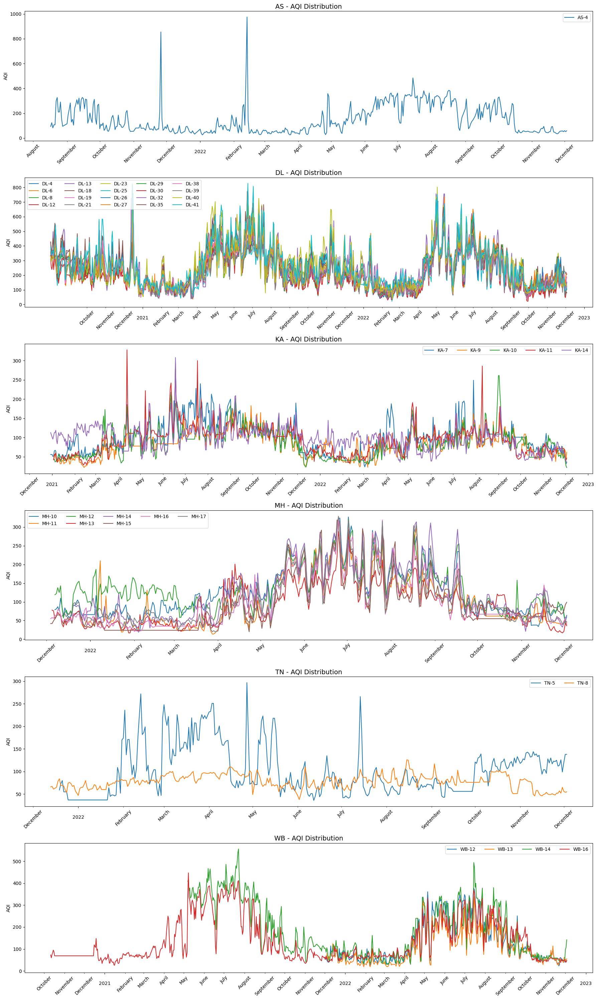

In [181]:
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(18,30))

for idx, code in enumerate(df.StateCode.unique()):
    count = 0
    for ss in mapping[code]:
        # if ss.startswith(code):
        ax = sns.lineplot(x=df[df.StateStation == ss].index, y=df[df.StateStation == ss].AQI, label=ss, ax=axes[idx])
        ax.xaxis.set_minor_locator(months)
        ax.xaxis.set_minor_formatter(monthsFmt)
        plt.setp(ax.xaxis.get_minorticklabels(), rotation=45)
        ax.xaxis.set_major_locator(years)
        ax.xaxis.set_major_formatter(yearsFmt)
        ax.legend(loc="best", ncols=5)
        ax.set_xlabel("")
    ax.set_title(f"{code} - AQI Distribution", fontsize=14)

plt.tight_layout()
plt.show()

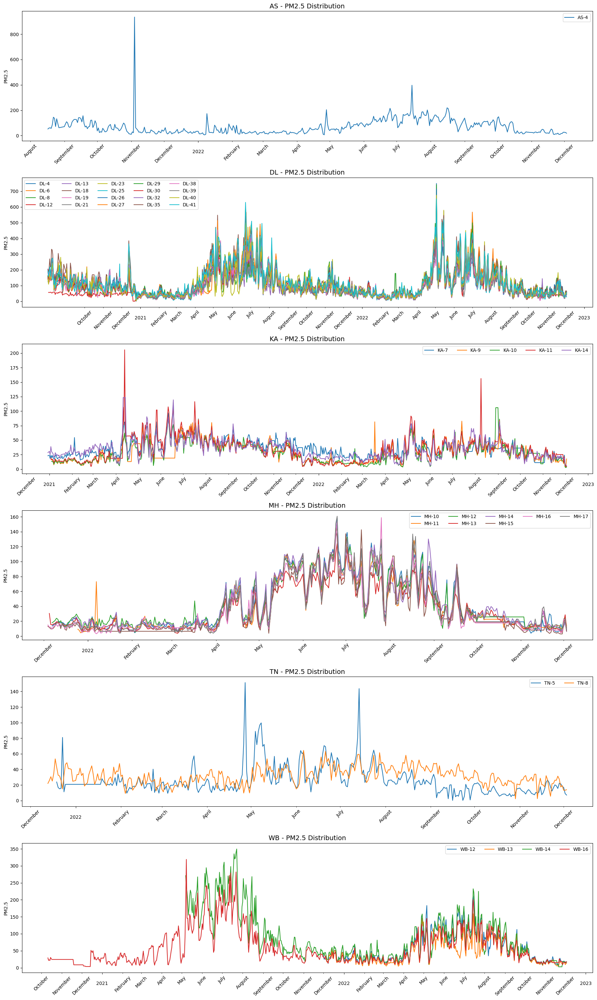

In [182]:
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(18,30))

for idx, code in enumerate(df.StateCode.unique()):
    count = 0
    for ss in mapping[code]:
        # if ss.startswith(code):
        ax = sns.lineplot(x=df[df.StateStation == ss].index, y=df[df.StateStation == ss]['PM2.5'], label=ss, ax=axes[idx])
        ax.xaxis.set_minor_locator(months)
        ax.xaxis.set_minor_formatter(monthsFmt)
        plt.setp(ax.xaxis.get_minorticklabels(), rotation=45)
        ax.xaxis.set_major_locator(years)
        ax.xaxis.set_major_formatter(yearsFmt)
        ax.legend(loc="best", ncols=5)
        ax.set_xlabel("")
    ax.set_title(f"{code} - PM2.5 Distribution", fontsize=14)

plt.tight_layout()
plt.show()

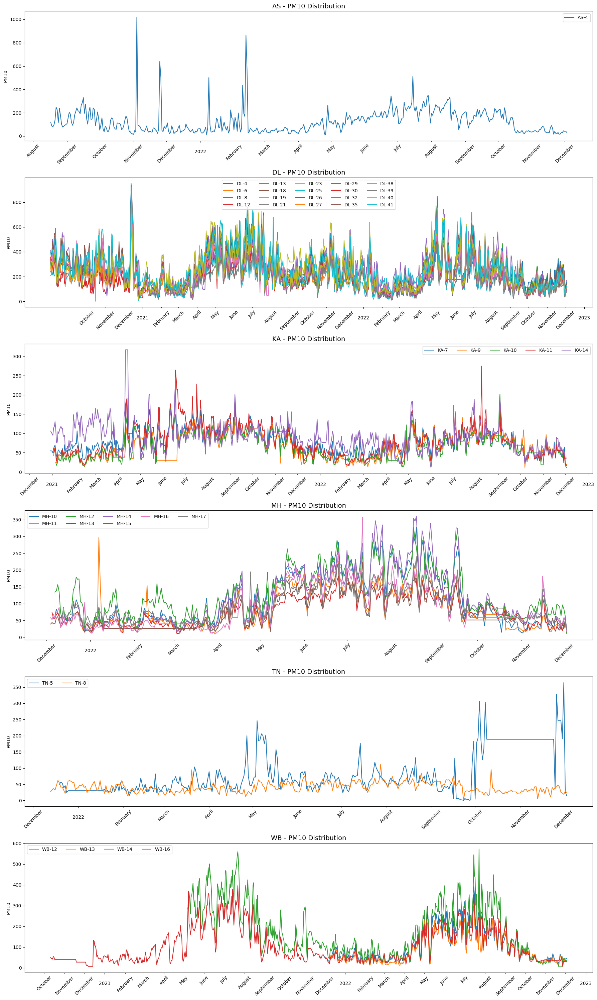

In [183]:
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(18,30))

for idx, code in enumerate(df.StateCode.unique()):
    count = 0
    for ss in mapping[code]:
        # if ss.startswith(code):
        ax = sns.lineplot(x=df[df.StateStation == ss].index, y=df[df.StateStation == ss]['PM10'], label=ss, ax=axes[idx])
        ax.xaxis.set_minor_locator(months)
        ax.xaxis.set_minor_formatter(monthsFmt)
        plt.setp(ax.xaxis.get_minorticklabels(), rotation=45)
        ax.xaxis.set_major_locator(years)
        ax.xaxis.set_major_formatter(yearsFmt)
        ax.legend(loc="best", ncols=5)
        ax.set_xlabel("")
    ax.set_title(f"{code} - PM10 Distribution", fontsize=14)

plt.tight_layout()
plt.show()

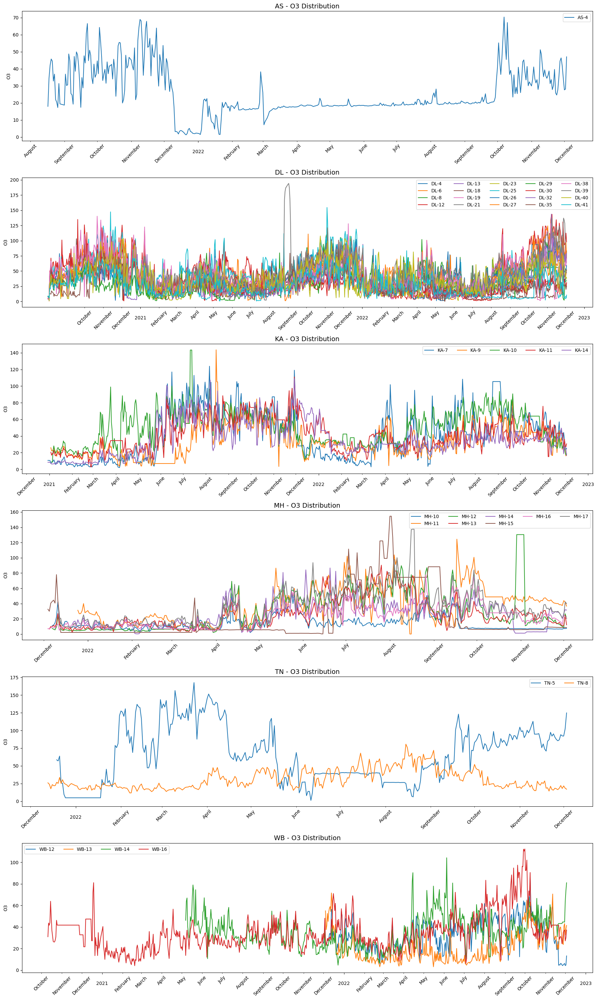

In [184]:
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(18,30))

for idx, code in enumerate(df.StateCode.unique()):
    count = 0
    for ss in mapping[code]:
        # if ss.startswith(code):
        ax = sns.lineplot(x=df[df.StateStation == ss].index, y=df[df.StateStation == ss]['O3'], label=ss, ax=axes[idx])
        ax.xaxis.set_minor_locator(months)
        ax.xaxis.set_minor_formatter(monthsFmt)
        plt.setp(ax.xaxis.get_minorticklabels(), rotation=45)
        ax.xaxis.set_major_locator(years)
        ax.xaxis.set_major_formatter(yearsFmt)
        ax.legend(loc="best", ncols=5)
        ax.set_xlabel("")
    ax.set_title(f"{code} - O3 Distribution", fontsize=14)

plt.tight_layout()
plt.show()

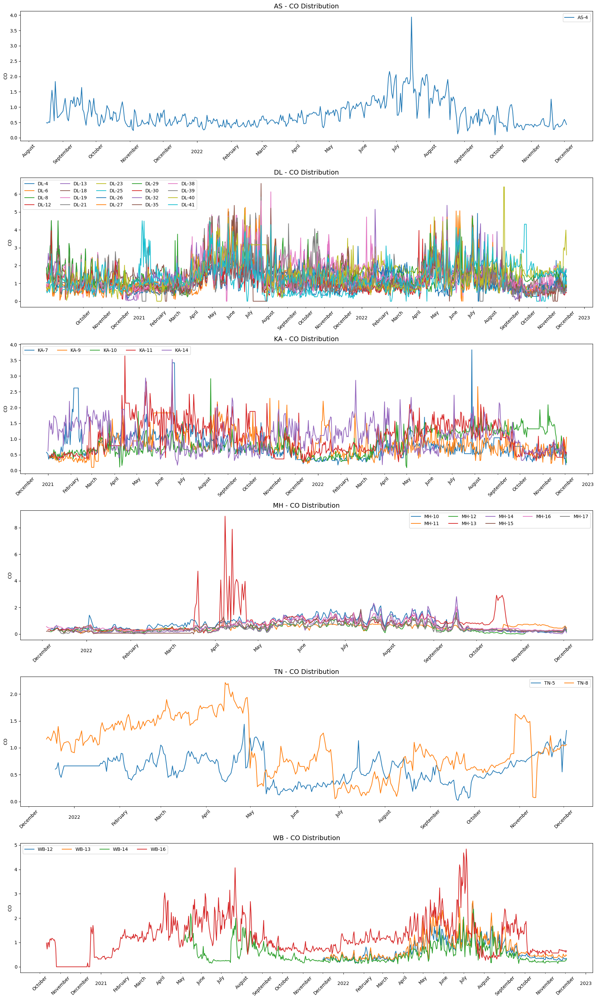

In [185]:
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(18,30))

for idx, code in enumerate(df.StateCode.unique()):
    count = 0
    for ss in mapping[code]:
        # if ss.startswith(code):
        ax = sns.lineplot(x=df[df.StateStation == ss].index, y=df[df.StateStation == ss]['CO'], label=ss, ax=axes[idx])
        ax.xaxis.set_minor_locator(months)
        ax.xaxis.set_minor_formatter(monthsFmt)
        plt.setp(ax.xaxis.get_minorticklabels(), rotation=45)
        ax.xaxis.set_major_locator(years)
        ax.xaxis.set_major_formatter(yearsFmt)
        ax.legend(loc="best", ncols=5)
        ax.set_xlabel("")
    ax.set_title(f"{code} - CO Distribution", fontsize=14)

plt.tight_layout()
plt.show()

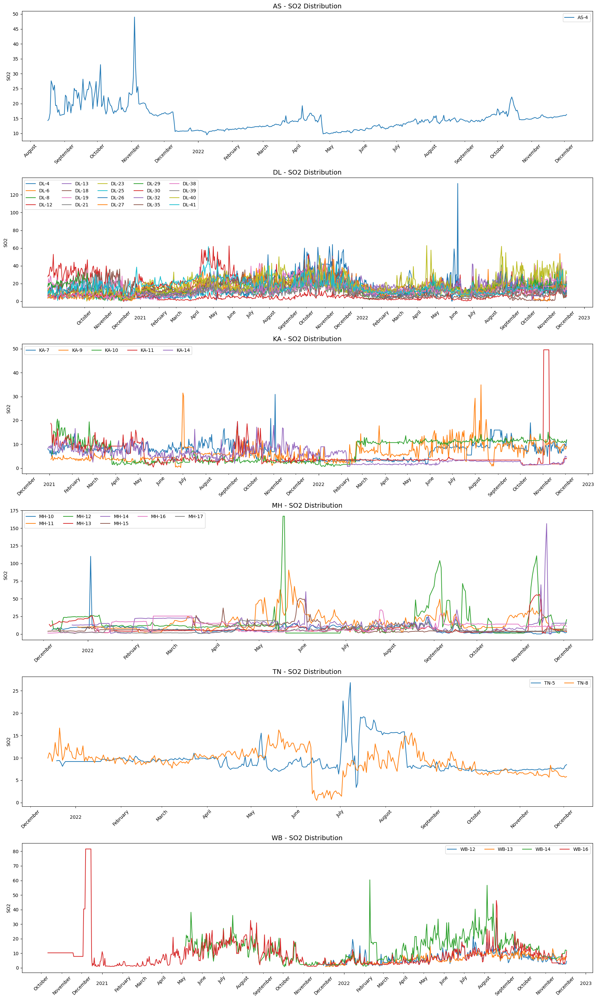

In [186]:
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(18,30))

for idx, code in enumerate(df.StateCode.unique()):
    count = 0
    for ss in mapping[code]:
        # if ss.startswith(code):
        ax = sns.lineplot(x=df[df.StateStation == ss].index, y=df[df.StateStation == ss]['SO2'], label=ss, ax=axes[idx])
        ax.xaxis.set_minor_locator(months)
        ax.xaxis.set_minor_formatter(monthsFmt)
        plt.setp(ax.xaxis.get_minorticklabels(), rotation=45)
        ax.xaxis.set_major_locator(years)
        ax.xaxis.set_major_formatter(yearsFmt)
        ax.legend(loc="best", ncols=5)
        ax.set_xlabel("")
    ax.set_title(f"{code} - SO2 Distribution", fontsize=14)

plt.tight_layout()
plt.show()

In [177]:
State=train.groupby("StateCode")[["PM2.5","PM10","O3","CO","SO2"]].mean().round()
State

,PM2.5,PM10,O3,CO,SO2
StateCode,,,,,
AS,69.0,126.0,26.0,1.0,15.0
DL,109.0,227.0,37.0,1.0,15.0
KA,33.0,75.0,40.0,1.0,6.0
MH,40.0,97.0,27.0,1.0,11.0
TN,29.0,61.0,48.0,1.0,9.0
WB,65.0,122.0,32.0,1.0,9.0


In [51]:
# ANALYSIS OF CITIES WITH DIFFERENT LEVELS

<Axes: title={'center': 'Parameters Levels in different cities'}, xlabel='Level', ylabel='City'>

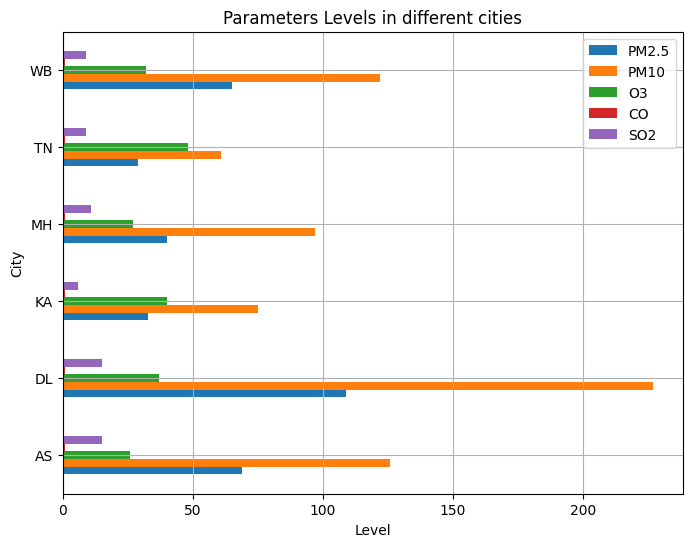

In [52]:
State.plot(figsize=(8,6),kind="barh",title="Parameters Levels in different cities",
                                                xlabel="Level", ylabel="City",grid=True)

<Axes: xlabel='StateCode', ylabel='AQI'>

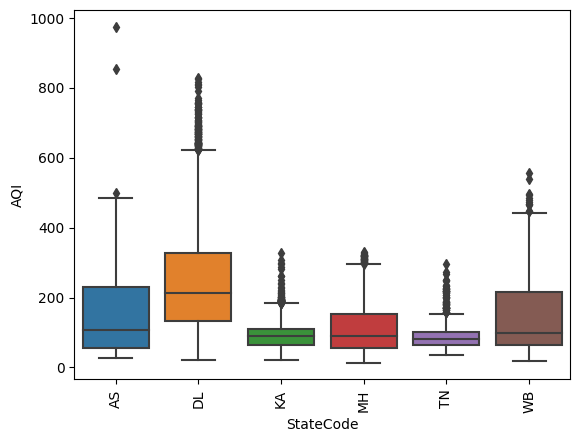

In [187]:
plt.xticks(rotation=90)
sns.boxplot(x="StateCode",y="AQI",data=train)